In [1]:
# 1. Import Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# 2. Load Dataset (Failsafe for both case_study2 and Downloads folder)
filename = "ecommerce_customer_segmentation_results.csv"
if not os.path.exists(filename):
    fallback = r"C:\Users\Arpita\OneDrive\Desktop\case_study2\ecommerce_customer_segmentation_results.csv"
    if os.path.exists(fallback):
        filename = fallback

df = pd.read_csv(filename)
print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (4334, 9)


,CustomerID,Recency,Frequency,Monetary,PCA1,PCA2,KMeans_Cluster,DBSCAN_eps_05,DBSCAN_eps_04
0,12346,326,1,77183.60,4.145342,5.500315,3,-1,-1
1,12347,2,7,4310.00,0.752765,-0.665509,0,0,0
2,12348,75,4,1437.24,0.004932,-0.190416,0,0,0
3,12349,19,1,1457.55,-0.044847,-0.745709,0,0,0
4,12350,310,1,294.40,-1.239656,1.824947,1,0,0


In [3]:
# 3. Data Cleaning & RFM Summary
# Remove duplicates and missing CustomerID
df = df.dropna(subset=["CustomerID"]).drop_duplicates()
df["CustomerID"] = df["CustomerID"].astype(int)

# Select the RFM columns
features = ["Recency", "Frequency", "Monetary"]
rfm = df[["CustomerID"] + features].copy()

print("Cleaned Customers Count:", len(rfm))
display(rfm[features].describe().round(2))

Cleaned Customers Count: 4334


,Recency,Frequency,Monetary
count,4334.00,4334.00,4334.00
mean,92.70,4.25,2015.97
std,100.18,7.63,8903.67
min,1.00,1.00,3.75
25%,18.00,1.00,304.24
50%,51.00,2.00,662.56
75%,143.00,5.00,1631.62
max,374.00,206.00,279138.02


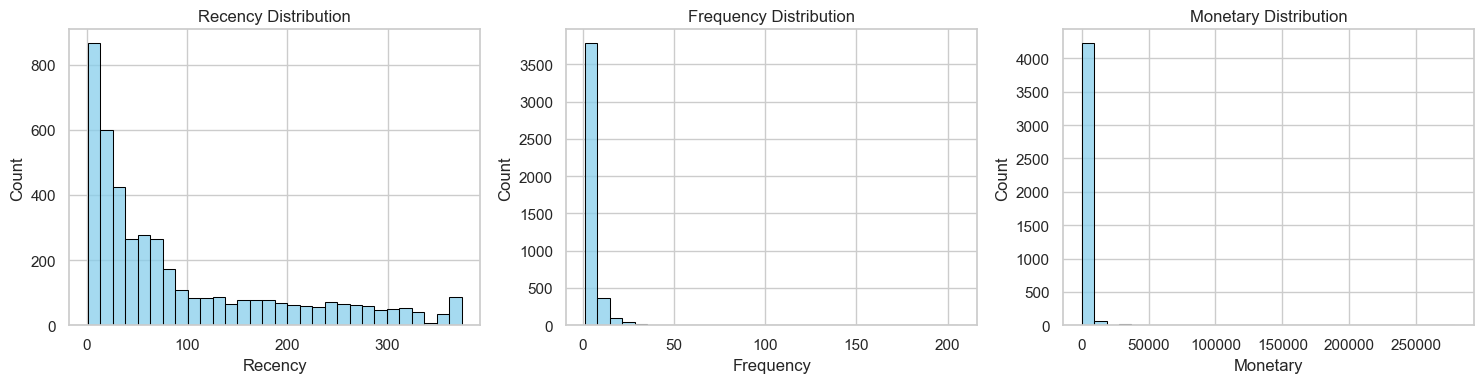

In [4]:
# 4. RFM Feature Distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, features):
    sns.histplot(rfm[col], bins=30, ax=ax, color="skyblue", edgecolor="black")
    ax.set_title(f"{col} Distribution")

plt.tight_layout()
plt.show()

In [5]:
# 5. Feature Scaling (StandardScaler)
# Brings Recency, Frequency, and Monetary to the same scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm[features])

print("Scaled Data Shape:", X_scaled.shape)
pd.DataFrame(X_scaled, columns=features).head()

Scaled Data Shape: (4334, 3)


,Recency,Frequency,Monetary
0,2.329115,-0.425192,8.443290
1,-0.905532,0.360754,0.257679
2,-0.176738,-0.032219,-0.065007
3,-0.735813,-0.425192,-0.062726
4,2.169379,-0.425192,-0.193378


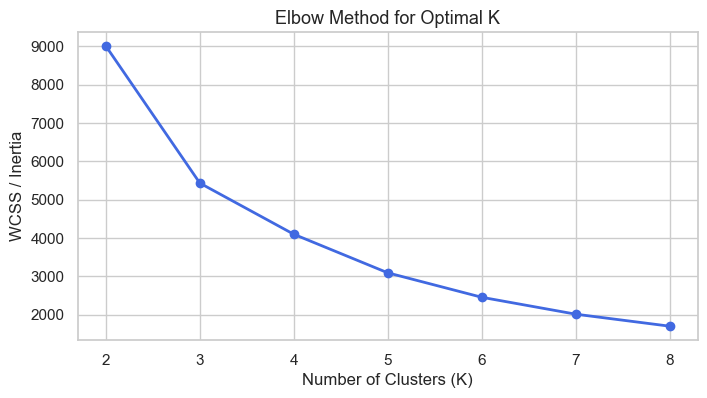

In [6]:
# 6. Elbow Method (Finding Best Number of Clusters K)
wcss = []
k_values = range(2, 9)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), wcss, marker="o", color="royalblue", linewidth=2)
plt.title("Elbow Method for Optimal K", fontsize=13)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.grid(True)
plt.show()

In [7]:
# 7. Train K-Means Model (K = 4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customers per Cluster:")
print(rfm["Cluster"].value_counts().sort_index())

print("\nAverage RFM Values per Cluster:")
cluster_profile = rfm.groupby("Cluster")[features].mean().round(2)
display(cluster_profile)

Customers per Cluster:
Cluster
0    3045
1    1066
2      13
3     210
Name: count, dtype: int64

Average RFM Values per Cluster:


,Recency,Frequency,Monetary
Cluster,,,
0,43.84,3.64,1322.51
1,248.54,1.54,474.12
2,7.38,81.77,125712.09
3,15.40,21.97,12240.55


Variance explained by 2 components: 85.57 %


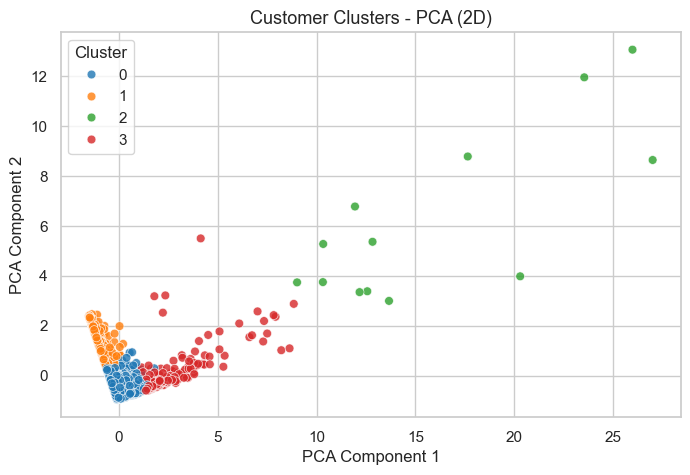

In [8]:
# 8. 2D Visualization using PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Variance explained by 2 components:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=rfm["Cluster"],
    palette="tab10",
    s=40,
    alpha=0.8
)
plt.title("Customer Clusters - PCA (2D)", fontsize=13)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

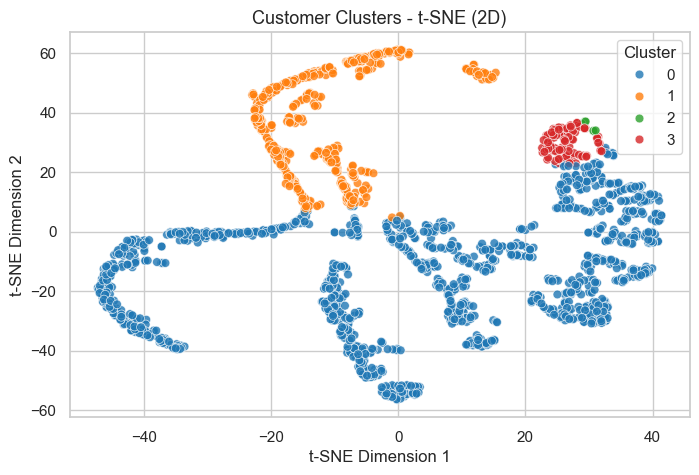

In [9]:
# 9. 2D Visualization using t-SNE
# Fast and safe sampling for t-SNE
sample_n = min(2000, len(X_scaled))
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled[:sample_n])

plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=rfm["Cluster"].iloc[:sample_n],
    palette="tab10",
    s=40,
    alpha=0.8
)
plt.title("Customer Clusters - t-SNE (2D)", fontsize=13)
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()